# k-means as an autoencoder (bivariate continuum-discrete model)
**ARPM script:** `s_autoencoders_kmeans` · **Labs:** Autoencoders, Least squares autoencoders, Unsupervised predictor: k-means

**In plain words:** a hidden coin flip $H$ decides which of two normal bells $X$ is drawn from.
We only see $X$. 2-means tries to recover the coin by drawing a cutoff $x_c^*$:

- **encoder** $\zeta(x) = 1\{x > x_c\}$ : squash $x$ into a 0/1 code
- **decoder** $\chi(z) = \mathbb{E}\{X|Z=z\}$ : rebuild $x$ as its cluster's average
- **error** = within-cluster variance $\mathbb{E}\{\mathbb{V}\{X|Z\}\}$; the rest of $\mathbb{V}\{X\}$ is between-cluster variance

The script compares an *arbitrary* cutoff (0.5) with the *optimal* k-means cutoff: the optimal one has lower within-cluster variance.

> **Change from ARPM's original:** `scipy.stats.norm.rvs(loc, scale, size)` takes the **standard deviation** as `scale`.
> ARPM passes the variance (`sigma2_x0`), so it simulates bells with sd 0.36 / 0.49 instead of 0.6 / 0.7, and the plotted pdf (which correctly uses `sqrt`) doesn't match the scenarios. Fixed below with `sqrt(...)`; the same trap is in Homework Task 1.

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
from numpy import array, where

from numpy import average, cov, full, linspace, r_, sum, sqrt
from numpy.random import binomial, seed
from scipy.stats import norm as normal
from sklearn.cluster import k_means
from seaborn import barplot, lineplot, scatterplot
from matplotlib.pyplot import fill, show

seed(42)  # added: reproducible runs

## 1. Generate Gaussian mixture scenarios for observable variable

In [6]:
# Bernoulli parameter of hidden variable (a single yes/no coin flip)
# The probability the coin lands on 1, here 40% of days are regime 1
p_h = 0.4
# number of Monte Carlo simulations (the number of coin flips, 100,000)
j_bar = 100000
# scenarios of hidden variable (array of 0 or 1 values(coin flips, 100,000 in total)
# with a bias to 40% ones
h = binomial(1, p_h, j_bar)

# conditional expectations (2 means/center points of the same variable X, 1 per regime)
# marking the mean/center point of each bell/distribution
mu_x0 = -1
mu_x1 = 1.5

# conditional variances (this indicates how wide each bell is)
# variance 0.36 is a standard deviation of 0.6
# variance 0.49 is a standard deviation of 0.7
# can play around with this having values like 0.05 would be small,
# and 2 clearly separate humps (find the regimes easily)
# having values like 2.0 both bells would have overlap (lots of misclassified points)
sigma2_x0 = 0.36
sigma2_x1 = 0.49

# scenarios of mixtures  (FIX: scale = standard deviation = sqrt(variance))
# for each bell of X is 100,000 draws for each regime
# draws random numbers from a normal bell
# loc = center(the mean), scale = std deviation (hence the sqrt()), size = j_bar -> how many draws
x_h0 = normal.rvs(mu_x0, sqrt(sigma2_x0), j_bar)
x_h1 = normal.rvs(mu_x1, sqrt(sigma2_x1), j_bar)

# scenarios of observable variable
x = (1 - h)*x_h0 + h*x_h1

                                                   target  simulated  abs_diff
P{H=1} prob the hidden coin lands on 1               0.40     0.4000    0.0000
E{X|H=0} avg of X, counting only regime 0 days      -1.00    -0.9976    0.0024
E{X|H=1} avg of X, counting only regime 1 days       1.50     1.4938    0.0062
V{X|H=0} spread of X, counting only regime 0 days    0.36     0.3606    0.0006
V{X|H=1} spread of X, counting only regime 1 days    0.49     0.4938    0.0038

All within 0.02 of target: True

    h   x_h0   x_h1  x (observed)
0  0 -0.494  2.950        -0.494
1  1  0.514  0.844         0.844
2  1 -1.060  1.261         1.261
3  0 -2.319  1.233        -2.319
4  0 -0.145  1.672        -0.145
5  0 -1.731  1.807        -1.731


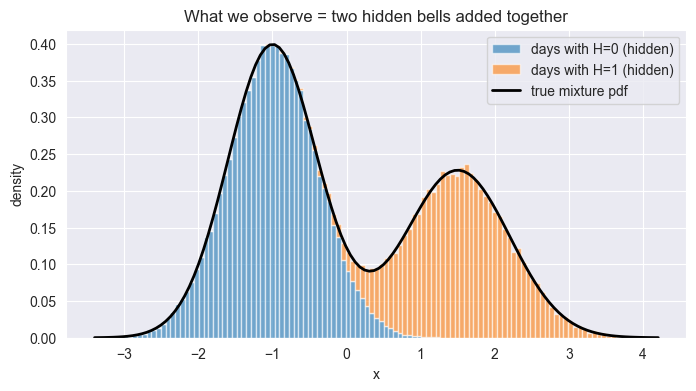

In [9]:
# ---- Step 1 check (my addition, not ARPM) ----------------------------------
# 1) Did the simulation give us what we asked for?

check = pd.DataFrame({
    "target":    [p_h, mu_x0, mu_x1, sigma2_x0, sigma2_x1],
    "simulated": [h.mean(), x[h == 0].mean(), x[h == 1].mean(),
                  x[h == 0].var(), x[h == 1].var()],
}, index=["P{H=1} prob the hidden coin lands on 1", "E{X|H=0} avg of X, counting only regime 0 days", "E{X|H=1} avg of X, counting only regime 1 days", "V{X|H=0} spread of X, counting only regime 0 days", "V{X|H=1} spread of X, counting only regime 1 days"])
check["abs_diff"] = (check["simulated"] - check["target"]).abs()
print(check.round(4))
print("\nAll within 0.02 of target:", bool((check["abs_diff"] < 0.02).all()))

# 2) The switch x = (1-h)*x_h0 + h*x_h1 in action: x copies x_h0 when h=0, x_h1 when h=1
print("\n", pd.DataFrame({"h": h, "x_h0": x_h0, "x_h1": x_h1,
                          "x (observed)": x}).head(6).round(3))

# 3) Drawing a Picture of the two hidden regimes (colours) to see if they stack up to what we observe
bins = linspace(x.min(), x.max(), 120)
width = bins[1] - bins[0]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist([x[h == 0], x[h == 1]], bins=bins, stacked=True, alpha=0.6,
        weights=[full((h == 0).sum(), 1 / (j_bar * width)),
                 full((h == 1).sum(), 1 / (j_bar * width))],
        label=["days with H=0 (hidden)", "days with H=1 (hidden)"])
pdf_mix = (1 - p_h)*normal(mu_x0, sqrt(sigma2_x0)).pdf(bins) + \
          p_h*normal(mu_x1, sqrt(sigma2_x1)).pdf(bins)
ax.plot(bins, pdf_mix, "k", lw=2, label="true mixture pdf")
ax.set(xlabel="x", ylabel="density",
       title="What we observe = two hidden bells added together")
ax.legend()
show()

## 2. Compute boundary point of optimal clustering

In [10]:
# k means algorithm
centroid, label, _ = k_means(x.reshape(-1, 1), 2, n_init=10)

# ensure that samples are properly labeled
if (centroid[1][0] < centroid[0][0]):
    label = 1 - label
    # swap 2 centroids
    centroid[0][0], centroid[1][0] = centroid[1][0], centroid[0][0]

# boundary point of optimal clustering
x_c_star = average([centroid[0][0], centroid[1][0]])
print('x_c_star =', round(x_c_star, 4))

x_c_star = 0.2638


## 3. Compute best encoder/decoder, within/between cluster variance and display optimal clustering

cv_x = 1.9037
e_cv_x_z = 0.3897
cv_e_x_z = 1.514
e_cv_x_z_star = 0.3794
cv_e_x_z_star = 1.5244


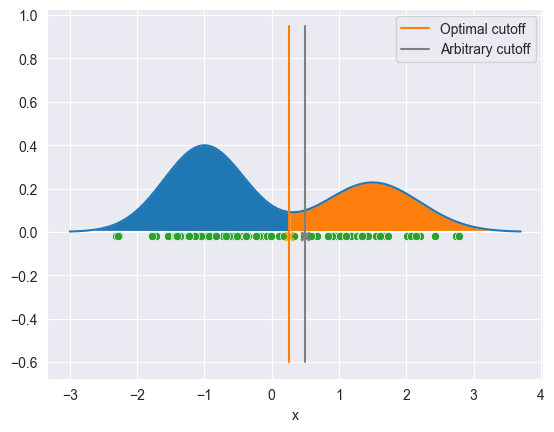

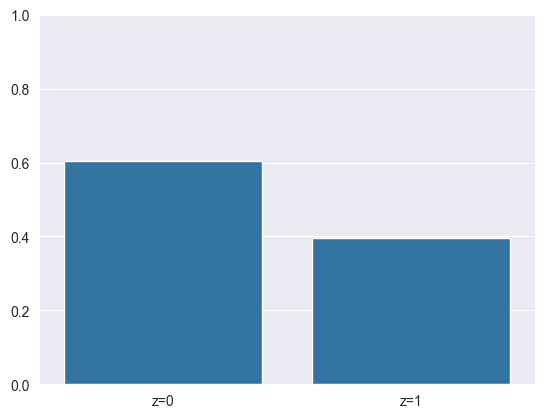

In [13]:
# arbitrary cutoff (you can change it)
x_c = 0.5
# encoder: True/False for each point
zeta = lambda x: x > x_c

# the code for all 100,000 days
z = zeta(x)

# Bernoulli parameter - how many days got code == 1
l_bar = sum(z==1)
# share of the days above the cutoff P{Z=1}
p = l_bar/j_bar

# scenarios of conditional observable variable given arbitrary code
x_z0 = x[z==0]
x_z1 = x[z==1]

# conditional expectations
e_x_z0 = average(x_z0)
e_x_z1 = average(x_z1)

# conditional variances
cv_x_z0 = cov(x_z0)
cv_x_z1 = cov(x_z1)

# total variance of target variable, V{X}
cv_x = cov(x)
# within-cluster variance
e_cv_x_z = (1 - p)*cv_x_z0 + p*cv_x_z1

# between-cluster variance
cv_e_x_z = cv_x - e_cv_x_z
print('cv_x =', cv_x.round(4))
print('e_cv_x_z =', e_cv_x_z.round(4))
print('cv_e_x_z =', cv_e_x_z.round(4))

# best encoder
zeta_c2_means = lambda x: x > x_c_star

# scenarios of optimal code
z_star = zeta_c2_means(x)
# Bernoulli parameter of best code
l_bar = sum(z_star==1)
p_star = l_bar/j_bar

# scenarios of conditional observable variable given best code

# split the data by code ("given Z=z")
x_z_star0 = x[z_star==0]
x_z_star1 = x[z_star==1]

# conditional expectations
# E{X|Z=0}, group 0's and 1's average's
e_x_z_star0 = average(x_z_star0)
e_x_z_star1 = average(x_z_star1)

# conditional variances
# V{X|Z=0}, group 0's and 1's spread's
cv_x_z_star0 = cov(x_z_star0)
cv_x_z_star1 = cov(x_z_star1)

# best decoder (rebuild task/half of the autoencoder)
# defined to show what th decoder is
chi_c2_means = lambda z: e_x_z_star0 if z == 0 else e_x_z_star1

# within-cluster variance
e_cv_x_z_star = (1 - p_star)*cv_x_z_star0 + p_star*cv_x_z_star1

# between-cluster variance
cv_e_x_z_star = cv_x - e_cv_x_z_star
print('e_cv_x_z_star =', e_cv_x_z_star.round(4))
print('cv_e_x_z_star =', cv_e_x_z_star.round(4))

# observable distribution
pdf_x = lambda x: (1 - p_h)*normal(mu_x0, sqrt(sigma2_x0)).pdf(x) +\
                   p_h*normal(mu_x1, sqrt(sigma2_x1)).pdf(x)

############################################ plots ############################################
grid = linspace(-3, 3.7, 600)  # grid

# split grid
grid0 = grid[grid <= x_c_star]
grid1 = grid[grid > x_c_star]

# optimal clustering
lineplot(x=grid, y=pdf_x(grid))
fill(r_[grid0, grid0[-1]], r_[pdf_x(grid0), 0])
fill(r_[grid1, grid1[0]], r_[pdf_x(grid1), 0])
lineplot(x=[x_c_star, x_c_star], y=[-0.6, 0.95], estimator=None, label='Optimal cutoff')
lineplot(x=[x_c, x_c], y=[-0.6, 0.95], estimator=None, color='grey', label='Arbitrary cutoff')
scatterplot(x=x[:100], y=full(100,-0.02)).set(xlabel='x')
scatterplot(x=[x_c_star], y=[-0.02], color='orange', marker='x', lw=2)
scatterplot(x=[x_c], y=[-0.02], color='grey', marker='x', lw=2); show();

# optimal code
barplot(x=['z=0', 'z=1'], y=[1-p_star, p_star]).set(ylim=(0, 1));

Total variance V{X} = 1.9037  (same for both: the data didn't change, only the cut)

                         arbitrary  k-means (optimal)  optimal − arbitrary
cutoff x_c                  0.5000             0.2638              -0.2362
P{Z=1}                      0.3723             0.3950               0.0227
decoder chi(0)=E{X|Z=0}    -0.9485            -0.9985              -0.0500
decoder chi(1)=E{X|Z=1}     1.5968             1.5271              -0.0697
within  E{V{X|Z}}           0.3897             0.3794              -0.0103
between V{E{X|Z}}           1.5140             1.5244               0.0103
between / total             0.7953             0.8007               0.0054
accuracy vs hidden H        0.9649             0.9730               0.0081
days misclassified       3511.0000          2699.0000            -812.0000

Encode → decode on the first 6 days (within-variance = average of the error column over ALL 100,000 days):
   x (observed)  h (hidden truth)  z = encode(x)  x_hat =

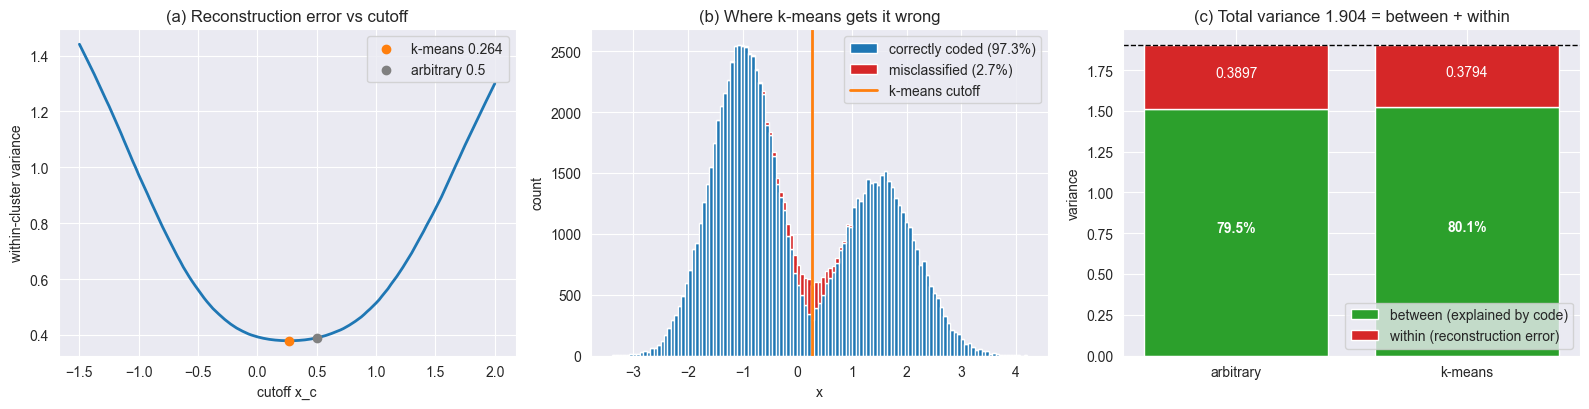

In [15]:
# ---- Step 3 explainer (my addition, not ARPM) -------------------------------
# ---------- 1) Scoreboard: arbitrary vs k-means encoder ----------
def score(code, cut):
    """Everything Step 3 computes for one encoder, plus how well it recovers the hidden H."""
    code = code.astype(int)
    p_ = code.mean()
    within = (1 - p_)*cov(x[code == 0]) + p_*cov(x[code == 1])
    return {
        "cutoff x_c":              cut,
        "P{Z=1}":                  p_,
        "decoder chi(0)=E{X|Z=0}": x[code == 0].mean(),
        "decoder chi(1)=E{X|Z=1}": x[code == 1].mean(),
        "within  E{V{X|Z}}":       within,
        "between V{E{X|Z}}":       cv_x - within,
        "between / total":         1 - within/cv_x,
        "accuracy vs hidden H":    (code == h).mean(),
        "days misclassified":      int((code != h).sum()),
    }

board = pd.DataFrame({"arbitrary": score(z, x_c), "k-means (optimal)": score(z_star, x_c_star)})
board["optimal − arbitrary"] = board["k-means (optimal)"] - board["arbitrary"]
print(f"Total variance V{{X}} = {cv_x:.4f}  (same for both: the data didn't change, only the cut)\n")
print(board.round(4).to_string())

# ---------- 2) The autoencoder in action on a few days ----------
demo = pd.DataFrame({"x (observed)": x[:6], "h (hidden truth)": h[:6]})
demo["z = encode(x)"] = z_star[:6].astype(int)
demo["x_hat = decode(z)"] = where(demo["z = encode(x)"] == 1, e_x_z_star1, e_x_z_star0)
demo["error (x − x_hat)²"] = (demo["x (observed)"] - demo["x_hat = decode(z)"])**2
demo["correct?"] = demo["z = encode(x)"] == demo["h (hidden truth)"]
print("\nEncode → decode on the first 6 days "
      "(within-variance = average of the error column over ALL 100,000 days):")
print(demo.round(3).to_string())

# ---------- 3) Pictures ----------
cuts = linspace(-1.5, 2.0, 141)
within_curve = array([(1 - (x > c).mean())*x[x <= c].var() + (x > c).mean()*x[x > c].var()
                      for c in cuts])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# (a) error vs cutoff: k-means sits at the bottom of the bowl
ax = axes[0]
ax.plot(cuts, within_curve, lw=2)
ax.scatter([x_c_star], [e_cv_x_z_star], color="tab:orange", zorder=3, label=f"k-means {x_c_star:.3f}")
ax.scatter([x_c], [e_cv_x_z], color="grey", zorder=3, label=f"arbitrary {x_c}")
ax.set(title="(a) Reconstruction error vs cutoff", xlabel="cutoff x_c", ylabel="within-cluster variance")
ax.legend()

# (b) where the mistakes are: correctly coded vs misclassified days
ax = axes[1]
bins = linspace(x.min(), x.max(), 120)
wrong = z_star.astype(int) != h
ax.hist([x[~wrong], x[wrong]], bins=bins, stacked=True, color=["tab:blue", "tab:red"],
        label=[f"correctly coded ({(~wrong).mean():.1%})", f"misclassified ({wrong.mean():.1%})"])
ax.axvline(x_c_star, color="tab:orange", lw=2, label="k-means cutoff")
ax.set(title="(b) Where k-means gets it wrong", xlabel="x", ylabel="count")
ax.legend()

# (c) variance split: same total, different within/between
ax = axes[2]
names = ["arbitrary", "k-means"]
within_v, between_v = [e_cv_x_z, e_cv_x_z_star], [cv_e_x_z, cv_e_x_z_star]
ax.bar(names, between_v, label="between (explained by code)", color="tab:green")
ax.bar(names, within_v, bottom=between_v, label="within (reconstruction error)", color="tab:red")
for i in range(2):
    ax.text(i, between_v[i]/2, f"{between_v[i]/cv_x:.1%}", ha="center", color="white", fontweight="bold")
    ax.text(i, between_v[i] + within_v[i]/2, f"{within_v[i]:.4f}", ha="center", color="white")
ax.axhline(cv_x, ls="--", color="k", lw=1)
ax.set(title=f"(c) Total variance {cv_x:.3f} = between + within", ylabel="variance")
ax.legend(loc="lower right")

plt.tight_layout(); show()

## Cross-check with `clustering_lab` (not ARPM code)
Same numbers from the reusable tools the pipelines will use.

In [17]:
# --- PyCharm plumbing (not ARPM code) -------------------------------------
# Find the unit root from wherever the notebook runs, so `clustering_lab`
# imports and the data path work in PyCharm, Jupyter or a test run.
import sys
from pathlib import Path

UNIT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "clustering_lab").is_dir())
if str(UNIT_ROOT) not in sys.path:
    sys.path.insert(0, str(UNIT_ROOT))

from clustering_lab.kmeans_tools import two_means_boundary, encode, variance_split

x_star_lab, _, _ = two_means_boundary(x)
split = variance_split(x, encode(x, x_star_lab))
print(f"x_c*      {x_star_lab:.4f}  (notebook {x_c_star:.4f})")
print(f"within    {split.within:.4f}  (notebook {e_cv_x_z_star:.4f})")
print(f"between   {split.between:.4f}  (notebook {cv_e_x_z_star:.4f})")
print(f"explained {split.r2_between:.1%} of total variance")

x_c*      0.2640  (notebook 0.2638)
within    0.3794  (notebook 0.3794)
between   1.5243  (notebook 1.5244)
explained 80.1% of total variance


Conclusion:
This notebook shows that k-means is an autoencoder, and that the cutoff it picks is the one
that loses the least information.

In 3 steps:
- Create a world where we know the answer, days secretly belong to 1 of 2 regimes
- Let k-means guess the regimes from X alone (finds 2 centers and puts the cutoff halfway between them (0.264)
The cutoff is the encoder "above or below" -> code 0 or 1
- Score the guess.  The decoder rebuilds each day as its groups average.  The error is the within-cluster variance, and whats left is the between cluster variance (explained)

What it teaches for the rest of the unit.
- Compression = learning structure - PCA squashes down into a few numbers, k-means squashes into a label.
- The law of total variance is the scorecard - total = within + between.  Between / total works like r_squared.
- k-means has limits (using distance only) - mixture models do the same job with probabilities.

Why a quant cares:  swap 2 bells for calm vs stressed markets, or for groups of stocks that move
together, and this is regime detection and stock clustering.  This is the toy version before other labs
test against real S&P data.